<a href="https://colab.research.google.com/github/AyubUmair/ComputerVision/blob/main/EN3160_A03_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

Epoch 1/20, Loss: 0.9769443565011025
Epoch 2/20, Loss: 0.9498461413383484
Epoch 3/20, Loss: 0.9361028322577476
Epoch 4/20, Loss: 0.927551677763462
Epoch 5/20, Loss: 0.9216139950156211
Epoch 6/20, Loss: 0.9172072034478188
Epoch 7/20, Loss: 0.9137934421896935
Epoch 8/20, Loss: 0.9110660901665688
Epoch 9/20, Loss: 0.9088366684913636
Epoch 10/20, Loss: 0.9069834507703781
Epoch 11/20, Loss: 0.9054228117465973
Epoch 12/20, Loss: 0.9040953183174133
Epoch 13/20, Loss: 0.9029557703733444
Epoch 14/20, Loss: 0.901972367823124
Epoch 15/20, Loss: 0.9011182242631912
Epoch 16/20, Loss: 0.9003728857636452
Epoch 17/20, Loss: 0.8997199481129646
Epoch 18/20, Loss: 0.8991462755203247
Epoch 19/20, Loss: 0.8986407877802849
Epoch 20/20, Loss: 0.8981939598917961


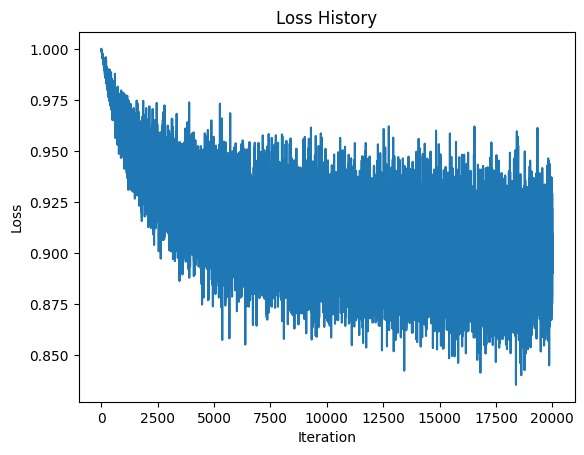

Training accuracy: 32.21%
Test accuracy: 32.44%


In [3]:

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
D_in = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10              # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(D_in, K) * std  # One layer: directly map input to output
b = torch.randn(K) * std

# Hyperparameters
iterations = 20
lr = 2e-6        # Learning rate
lr_decay = 0.9   # Learning rate decay
reg = 0          # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, D_in)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one hot

        # Forward pass
        y_pred = x_train.mm(w) + b  # Output layer activation

        # Loss calculation (Mean Squared Error with regularization)
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t+1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

100%|██████████| 170M/170M [44:37<00:00, 63.7kB/s]


Epoch 1/10, Loss: 1.9067795144319535
Epoch 2/10, Loss: 1.7251947385072708
Epoch 3/10, Loss: 1.6601325924396515
Epoch 4/10, Loss: 1.6129678704738617
Epoch 5/10, Loss: 1.5707513506412507
Epoch 6/10, Loss: 1.535611364364624
Epoch 7/10, Loss: 1.5050501029491425
Epoch 8/10, Loss: 1.4759855918884277
Epoch 9/10, Loss: 1.4502022240161896
Epoch 10/10, Loss: 1.4262510246038438


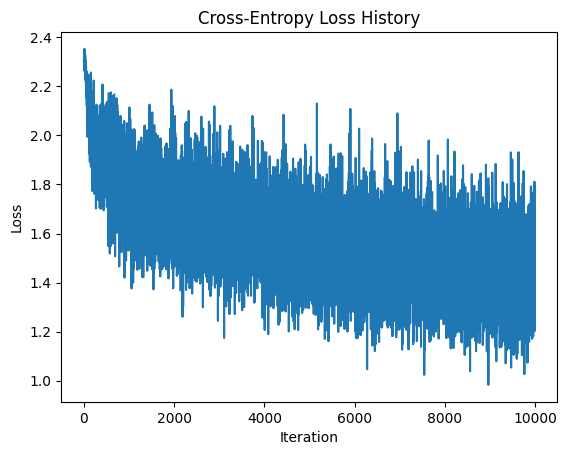

Training accuracy: 52.95%
Test accuracy: 48.10%


In [2]:
# 1. Dataloading (CIFAR-10)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

# 2. Define Network Parameters
D_in = 3 * 32 * 32
H = 100  # Hidden layer nodes
K = 10
std = 1e-2  # Slightly larger std usually helps manual multi-layer init

# Initialize weights and biases for two layers
w1 = torch.randn(D_in, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10  # Reduced to 10 epochs
lr = 0.1         # Learning rate tuned for Cross-Entropy
lr_decay = 0.95
reg = 1e-4
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for inputs, labels in trainloader:
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)      # Sigmoid activation
        z2 = a1.mm(w2) + b2         # Output layer logits

        # Softmax and Cross-Entropy Loss
        # Shift z2 for numerical stability
        z2_shifted = z2 - torch.max(z2, dim=1, keepdim=True).values
        exp_scores = torch.exp(z2_shifted)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)

        corect_logprobs = -torch.log(probs[range(Ntr), labels])
        loss = torch.sum(corect_logprobs) / Ntr + reg * (torch.sum(w1**2) + torch.sum(w2**2))

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # Gradient of Cross-Entropy + Softmax w.r.t z2
        dz2 = probs.clone()
        dz2[range(Ntr), labels] -= 1
        dz2 /= Ntr

        # Gradients for Layer 2
        dw2 = a1.t().mm(dz2) + 2 * reg * w2
        db2 = dz2.sum(dim=0)

        # Backprop through Sigmoid to Layer 1
        da1 = dz2.mm(w2.t())
        dz1 = da1 * a1 * (1.0 - a1) # Sigmoid derivative

        # Gradients for Layer 1
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{iterations}, Loss: {running_loss / len(trainloader)}")
    lr *= lr_decay

# 4. Plotting
plt.plot(loss_history)
plt.title("Cross-Entropy Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5 & 6. Calculate Accuracy Helper
def evaluate_accuracy(loader, w1, b1, w2, b2):
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            z1 = x.mm(w1) + b1
            a1 = torch.sigmoid(z1)
            z2 = a1.mm(w2) + b2
            predicted = torch.argmax(z2, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

print(f"Training accuracy: {evaluate_accuracy(trainloader, w1, b1, w2, b2):.2f}%")
print(f"Test accuracy: {evaluate_accuracy(testloader, w1, b1, w2, b2):.2f}%")
